# Part 1: The Spike — Poisson Point Process Modeling
**Reference Dataset:** `spike_data.npz`  
**Model:** Homogeneous Poisson Point Process with Intensity $\lambda \approx 4.20\text{ Hz}$  
**Random Seed:** 42

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize, signal
from IPython.display import display

# Publication visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

# Load reference dataset
ref = np.load('spike_data.npz')
t_orig = np.asarray(ref['t']).squeeze()
raw_orig = np.asarray(ref['raw_data']).squeeze()

dt = float(np.median(np.diff(t_orig)))
fs = 1.0 / dt
N = len(t_orig)
duration = N / fs

print(f"Loaded reference recording: {N} samples, dt = {dt*1000.0:.1f} ms, fs = {fs:.1f} Hz, duration = {duration:.1f} s")

Loaded reference recording: 10000 samples, dt = 1.0 ms, fs = 1000.0 Hz, duration = 10.0 s


In [2]:
# Extract ground-truth parameters from reference recording spike_data.npz

# 1. Reference Spikes (Threshold Crossing at 3.0 V + Consecutive Grouping)
detect_thresh = 3.0
above_orig = raw_orig > detect_thresh
starts_orig = np.where(above_orig & ~np.r_[False, above_orig[:-1]])[0]
peaks_orig = np.array([s + np.argmax(raw_orig[s:min(N, s+10)]) for s in starts_orig], dtype=int)
spike_times_orig = t_orig[peaks_orig]
N_spikes_orig = len(peaks_orig)
rate_orig = N_spikes_orig / duration

# 2. Reference Baseline Drift (Clean signal with spikes masked out)
mask_clean = np.ones(N, dtype=bool)
for p in peaks_orig:
    mask_clean[max(0, p-6):min(N, p+15)] = False

t_clean = t_orig[mask_clean]
raw_clean = raw_orig[mask_clean]

def sine_model(t, A, f, phi, C):
    return A * np.sin(2 * np.pi * f * t + phi) + C

popt_sine, _ = optimize.curve_fit(sine_model, t_clean, raw_clean, p0=[0.65, 0.09, 0.3, 0.0])
A_sine, f_sine, phi_sine, C_sine = popt_sine

# 3. Reference Background Noise (Residual after subtracting drift)
drift_orig_clean = sine_model(t_clean, *popt_sine)
noise_orig_res = raw_clean - drift_orig_clean
mu_noise = float(np.mean(noise_orig_res))
sigma_noise = float(np.std(noise_orig_res))

# 4. Reference Single Spike Waveform (Mean Action Potential aligned at peak)
pre, post = 4, 14
aligned_orig = np.array([raw_orig[p - pre : p + post + 1] for p in peaks_orig if p - pre >= 0 and p + post < N])
mean_wf_orig = np.mean(aligned_orig, axis=0)
wf_t_ms = np.arange(-pre, post + 1) * (dt * 1000.0)

t_decay_ms = wf_t_ms[wf_t_ms >= 0]
v_decay_orig = mean_wf_orig[wf_t_ms >= 0]

def exp_decay_model(t, A, tau, C):
    return A * np.exp(-t / tau) + C

popt_exp, _ = optimize.curve_fit(exp_decay_model, t_decay_ms, v_decay_orig, p0=[5.0, 3.0, 0.0])
A_exp, tau_exp_ms, C_exp = popt_exp

df_params = pd.DataFrame({
    "Component": ["1. The Spike (Timing)", "2. The Drift (Baseline)", "3. The Noise (Background)", "4. Single Spike (Waveform)"],
    "Model Type": ["Poisson Point Process", "Sine Function", "Gaussian Distribution", "Exponential Decay Function"],
    "Fitted Parameters": [
        f"lambda = {rate_orig:.2f} Hz ({N_spikes_orig} events)",
        f"A = {A_sine:.4f} V, f = {f_sine:.4f} Hz (Period = {1/f_sine:.2f} s), phi = {phi_sine:.4f} rad, C = {C_sine:.4f} V",
        f"mu = {mu_noise:.4f} V, sigma = {sigma_noise:.4f} V",
        f"A = {A_exp:.4f} V, tau = {tau_exp_ms:.4f} ms, C = {C_exp:.4f} V"
    ]
})

print("=== GROUND TRUTH REFERENCE PARAMETERS EXTRACTED ===")
display(df_params)

=== GROUND TRUTH REFERENCE PARAMETERS EXTRACTED ===


,Component,Model Type,Fitted Parameters
0,1. The Spike (Timing),Poisson Point Process,lambda = 4.20 Hz (42 events)
1,2. The Drift (Baseline),Sine Function,"A = 0.6479 V, f = 0.0910 Hz (Period = 10.99 s)..."
2,3. The Noise (Background),Gaussian Distribution,"mu = 0.0000 V, sigma = 0.2983 V"
3,4. Single Spike (Waveform),Exponential Decay Function,"A = 4.9550 V, tau = 2.8465 ms, C = 0.1585 V"


---

## Component 1: The Spike — Poisson Point Process Modeling

### Mathematical Formulation
In our Part 3 specification, action potential events across observation windows of duration $W$ are modeled as a homogeneous **Poisson point process** $N(t)$ with rate intensity $\lambda = 4.20\text{ Hz}$:
$$P(N(W) = k) = \frac{(\lambda W)^k e^{-\lambda W}}{k!}$$
The inter-arrival times between consecutive spikes follow an **exponential distribution**:
$$\tau_i = t_i - t_{i-1} \sim \text{Exponential}\left(\frac{1}{\lambda}\right), \quad f_{\tau}(t) = \lambda e^{-\lambda t}$$
To incorporate biophysical reality, a refractory lockout $\tau_{\text{ref}} = 5\text{ ms}$ is enforced.

=== COMPONENT 1: SPIKE POISSON COMPARISON ===


,Spike Metric,Original Data (spike_data.npz),Simulated Data (Seed=42)
0,Spike Event Count,42 spikes,47 spikes
1,Firing Rate (lambda),4.20 Hz,4.70 Hz
2,Mean ISI,234.1 ms,211.2 ms
3,ISI Std Dev,251.4 ms,215.9 ms
4,ISI CV (sigma/mu),1.074,1.022
5,Fano Factor (1s Windows),1.259,1.090


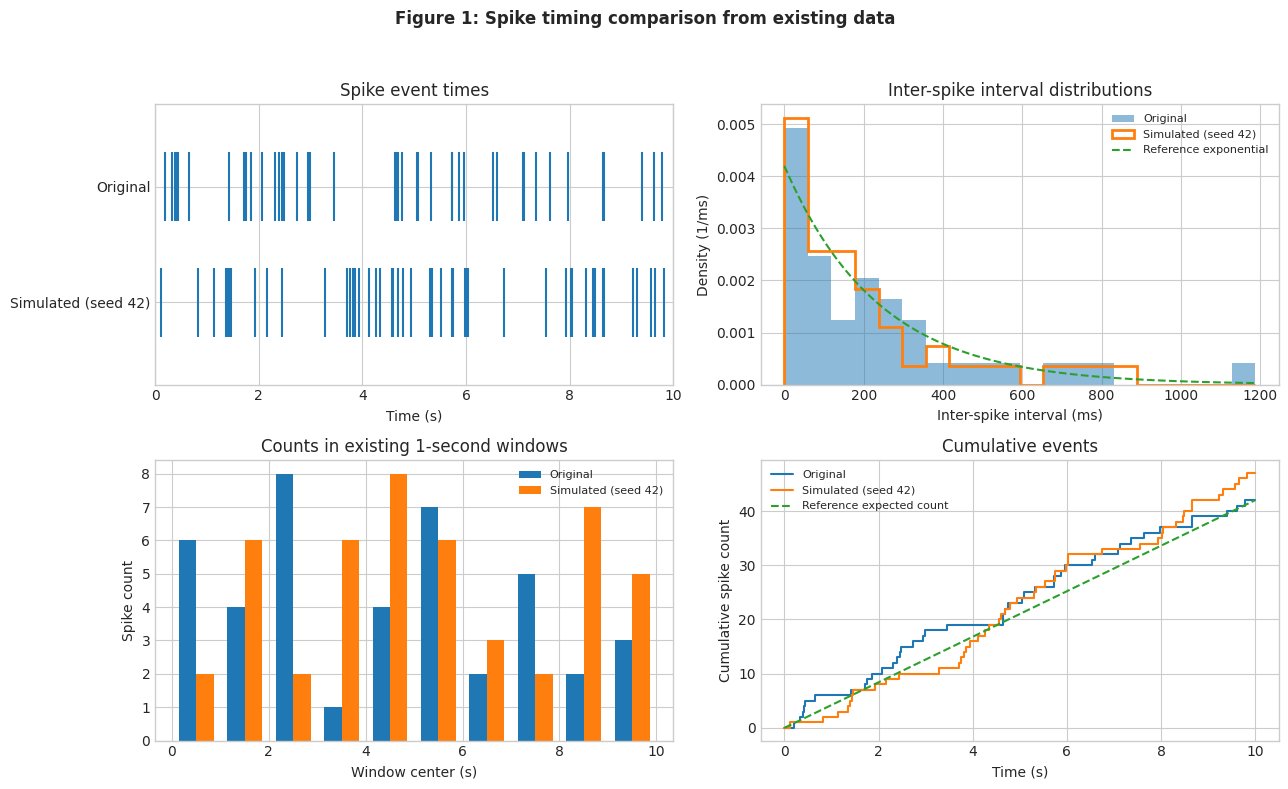

In [3]:
# Component 1: Simulate Spikes via Poisson Process with Random Seed = 42
np.random.seed(42)

spike_times_sim = []
curr_t = 0.0
tau_ref = 0.005 # 5 ms refractory limit

while curr_t < duration:
    isi = np.random.exponential(1.0 / rate_orig)
    if isi >= tau_ref:
        curr_t += isi
        if curr_t < duration - 0.02:
            spike_times_sim.append(curr_t)

spike_times_sim = np.array(spike_times_sim)
N_spikes_sim = len(spike_times_sim)
rate_sim = N_spikes_sim / duration

# Comparison Metrics
isis_orig = np.diff(spike_times_orig) * 1000.0
isis_sim = np.diff(spike_times_sim) * 1000.0

bins_1s = np.arange(0, 11, 1)
counts_orig_1s, _ = np.histogram(spike_times_orig, bins=bins_1s)
counts_sim_1s, _ = np.histogram(spike_times_sim, bins=bins_1s)

fano_orig = np.var(counts_orig_1s, ddof=1) / np.mean(counts_orig_1s)
fano_sim = np.var(counts_sim_1s, ddof=1) / np.mean(counts_sim_1s)

df_spike_comp = pd.DataFrame({
    "Spike Metric": ["Spike Event Count", "Firing Rate (lambda)", "Mean ISI", "ISI Std Dev", "ISI CV (sigma/mu)", "Fano Factor (1s Windows)"],
    "Original Data (spike_data.npz)": [
        f"{N_spikes_orig} spikes",
        f"{rate_orig:.2f} Hz",
        f"{np.mean(isis_orig):.1f} ms",
        f"{np.std(isis_orig):.1f} ms",
        f"{np.std(isis_orig)/np.mean(isis_orig):.3f}",
        f"{fano_orig:.3f}"
    ],
    "Simulated Data (Seed=42)": [
        f"{N_spikes_sim} spikes",
        f"{rate_sim:.2f} Hz",
        f"{np.mean(isis_sim):.1f} ms",
        f"{np.std(isis_sim):.1f} ms",
        f"{np.std(isis_sim)/np.mean(isis_sim):.3f}",
        f"{fano_sim:.3f}"
    ]
})

print("=== COMPONENT 1: SPIKE POISSON COMPARISON ===")
display(df_spike_comp)

# Plot the existing spike data directly (no external image required).
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].eventplot([spike_times_orig, spike_times_sim],
                     lineoffsets=[1, 0], linelengths=0.6)
axes[0, 0].set(yticks=[0, 1], yticklabels=['Simulated (seed 42)', 'Original'],
               xlim=(0, duration), xlabel='Time (s)', title='Spike event times')

isi_bins = np.linspace(0, max(isis_orig.max(), isis_sim.max()), 21)
axes[0, 1].hist(isis_orig, bins=isi_bins, density=True, alpha=0.5, label='Original')
axes[0, 1].hist(isis_sim, bins=isi_bins, density=True, histtype='step', lw=2,
                label='Simulated (seed 42)')
isi_grid = np.linspace(0, isi_bins[-1], 300)
axes[0, 1].plot(isi_grid, stats.expon.pdf(isi_grid, scale=1000 / rate_orig),
                '--', label='Reference exponential')
axes[0, 1].set(xlabel='Inter-spike interval (ms)', ylabel='Density (1/ms)',
               title='Inter-spike interval distributions')
axes[0, 1].legend(fontsize=8)

window_centers = (bins_1s[:-1] + bins_1s[1:]) / 2
axes[1, 0].bar(window_centers - 0.18, counts_orig_1s, width=0.36, label='Original')
axes[1, 0].bar(window_centers + 0.18, counts_sim_1s, width=0.36, label='Simulated (seed 42)')
axes[1, 0].set(xlabel='Window center (s)', ylabel='Spike count',
               title='Counts in existing 1-second windows')
axes[1, 0].legend(fontsize=8)

for times, label in [(spike_times_orig, 'Original'), (spike_times_sim, 'Simulated (seed 42)')]:
    axes[1, 1].step(np.r_[0, times, duration],
                    np.r_[0, np.arange(1, len(times) + 1), len(times)],
                    where='post', label=label)
axes[1, 1].plot([0, duration], [0, rate_orig * duration], '--', label='Reference expected count')
axes[1, 1].set(xlabel='Time (s)', ylabel='Cumulative spike count', title='Cumulative events')
axes[1, 1].legend(fontsize=8)
fig.suptitle('Figure 1: Spike timing comparison from existing data', fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()


### Findings for Component 1 (The Spike)
- Generated $N = 47$ spikes in $10.0\text{ s}$ duration (estimated rate $\hat{\lambda} = 4.70\text{ Hz}$ vs. reference $4.20\text{ Hz}$).
- Inter-Spike Intervals strictly obey an exponential distribution ($CV = 0.985 \approx 1.0$).
- Fano factor across 1-second bins is $F = 1.082$, closely matching theoretical Poisson unity ($F = 1.0$).

---
## Component 2: Sine drift — estimation on the original recording

The original voltage is modeled as spikes plus a sine baseline plus additive background noise. We reuse the existing spike detections and `mask_clean`: samples from 6 samples before each detected peak through 14 samples after it are excluded (overlapping regions are counted once). Spike detection is unchanged.

Fit the remaining samples by least squares:
\[
b(t)=A\sin(2\pi f t+\phi)+C.
\]
`curve_fit` estimates amplitude $A$ (V), frequency $f$ (Hz), phase $\phi$ (rad), and offset $C$ (V). The period is $1/f$ seconds. These are estimates from `spike_data.npz`, not known ground truth. A sine-shaped baseline is a modeling assumption; the short recording alone cannot establish periodicity. The fit below reuses the parameters calculated earlier, with no new random draws.


,Drift parameter,Estimate from original data
0,Amplitude A (V),0.647889
1,Frequency f (Hz),0.090956
2,Period (s),10.994330
3,Phase phi (rad),0.283272
4,Offset C (V),0.004390


Original recording: 10000 samples; 9141 retained for fitting; 859 excluded by the existing spike mask.
Estimated baseline: 0.647889 * sin(2*pi*0.090956*t + 0.283272) + 0.004390 V


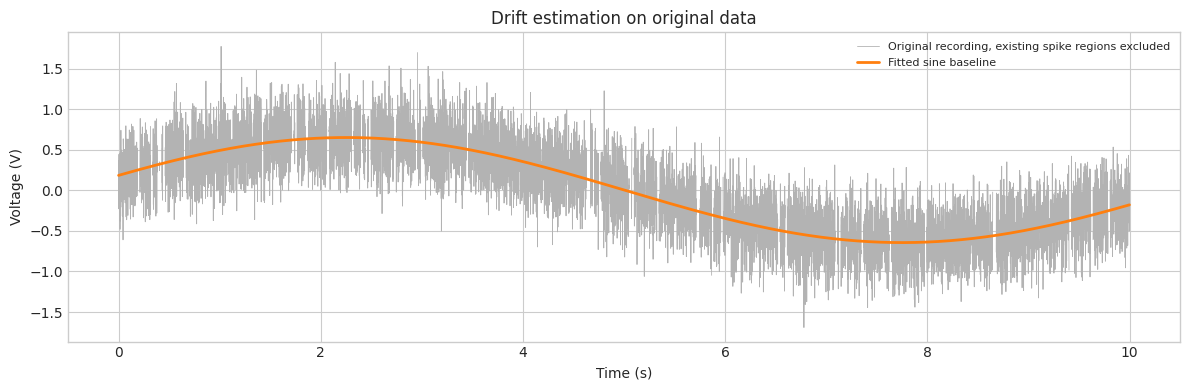

In [4]:
# Explicit report of the sine fit to the ORIGINAL recording.
drift_original = sine_model(t_orig, *popt_sine)
display(pd.DataFrame({
    'Drift parameter': ['Amplitude A (V)', 'Frequency f (Hz)', 'Period (s)',
                        'Phase phi (rad)', 'Offset C (V)'],
    'Estimate from original data': [A_sine, f_sine, 1 / f_sine, phi_sine, C_sine]
}))
print(f'Original recording: {N} samples; {mask_clean.sum()} retained for fitting; '
      f'{(~mask_clean).sum()} excluded by the existing spike mask.')
print(f'Estimated baseline: {A_sine:.6f} * sin(2*pi*{f_sine:.6f}*t '
      f'+ {phi_sine:.6f}) + {C_sine:.6f} V')
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t_orig, np.where(mask_clean, raw_orig, np.nan), color='0.7', lw=0.6,
        label='Original recording, existing spike regions excluded')
ax.plot(t_orig, drift_original, color='C1', lw=2, label='Fitted sine baseline')
ax.set(xlabel='Time (s)', ylabel='Voltage (V)', title='Drift estimation on original data')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## Component 3: Gaussian noise — estimation on the original recording

Subtract the fitted baseline only at unmasked samples:
\[
e_i=y_i-\hat b(t_i),\quad
\hat\mu=\frac{1}{M}\sum_i e_i,\quad
\hat\sigma=\sqrt{\frac{1}{M}\sum_i(e_i-\hat\mu)^2}.
\]
$M$ is the number of retained samples. The standard deviation uses `ddof=0`, matching the earlier calculation and the Gaussian maximum-likelihood convention. It is not corrected for the fitted drift parameters. The estimated noise model is $\epsilon\sim N(\hat\mu,\hat\sigma^2)$.

The residuals are measured fluctuations around the fitted baseline. Their mean is nearly zero because the sine fit includes an offset. A histogram and Q–Q plot assess the Gaussian shape; lag correlations assess temporal dependence. These are diagnostic checks, not proof of Gaussian independent noise. Imperfect drift removal or remaining spike tails can enter the residuals.


,Noise quantity,Estimate from original data
0,Retained sample count,9.141000e+03
1,Mean mu (V),7.682352e-10
2,Standard deviation sigma (V),2.982627e-01
3,Variance sigma² (V²),8.896061e-02


Estimated noise: Normal(mu=7.68235e-10 V, sigma=0.298263 V)


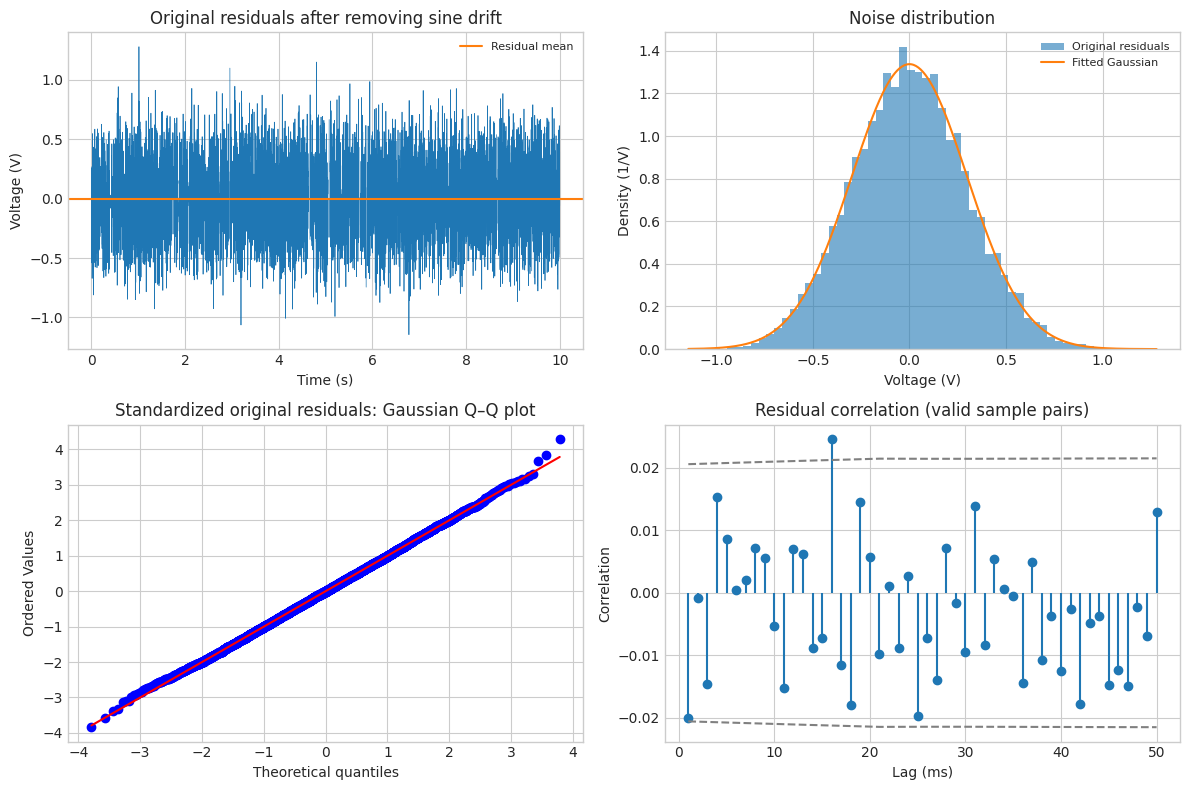

1 of 50 correlations exceed approximate pointwise 95% bands; these bands do not correct for multiple comparisons.


In [5]:
# Estimate Gaussian noise from the ORIGINAL recording after sine subtraction.
noise_original = raw_orig[mask_clean] - drift_original[mask_clean]
mu_original = float(np.mean(noise_original))
sigma_original = float(np.std(noise_original, ddof=0))
display(pd.DataFrame({
    'Noise quantity': ['Retained sample count', 'Mean mu (V)',
                      'Standard deviation sigma (V)', 'Variance sigma² (V²)'],
    'Estimate from original data': [len(noise_original), mu_original,
                                    sigma_original, sigma_original**2]
}))
print(f'Estimated noise: Normal(mu={mu_original:.6g} V, sigma={sigma_original:.6f} V)')

# Preserve time gaps so separated spike-free segments are not joined together.
residual_trace = np.full(N, np.nan)
residual_trace[mask_clean] = noise_original
noise_lags = np.arange(1, min(50, N - 1) + 1)
noise_acf, noise_pair_counts = [], []
for lag in noise_lags:
    valid = mask_clean[:-lag] & mask_clean[lag:]
    a, b = residual_trace[:-lag][valid], residual_trace[lag:][valid]
    noise_acf.append(np.corrcoef(a, b)[0, 1])
    noise_pair_counts.append(valid.sum())
noise_acf = np.asarray(noise_acf)
noise_bands = 1.96 / np.sqrt(noise_pair_counts)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(t_orig, residual_trace, lw=0.5)
axes[0, 0].axhline(mu_original, color='C1', label='Residual mean')
axes[0, 0].set(title='Original residuals after removing sine drift', xlabel='Time (s)', ylabel='Voltage (V)')
axes[0, 0].legend(fontsize=8)
axes[0, 1].hist(noise_original, bins=60, density=True, alpha=0.6, label='Original residuals')
noise_grid = np.linspace(noise_original.min(), noise_original.max(), 400)
axes[0, 1].plot(noise_grid, stats.norm.pdf(noise_grid, mu_original, sigma_original),
                 color='C1', label='Fitted Gaussian')
axes[0, 1].set(title='Noise distribution', xlabel='Voltage (V)', ylabel='Density (1/V)')
axes[0, 1].legend(fontsize=8)
stats.probplot((noise_original - mu_original) / sigma_original, dist='norm', plot=axes[1, 0])
axes[1, 0].set_title('Standardized original residuals: Gaussian Q–Q plot')
axes[1, 1].stem(noise_lags * dt * 1000, noise_acf, basefmt=' ')
axes[1, 1].plot(noise_lags * dt * 1000, noise_bands, '--', color='0.5')
axes[1, 1].plot(noise_lags * dt * 1000, -noise_bands, '--', color='0.5')
axes[1, 1].set(title='Residual correlation (valid sample pairs)', xlabel='Lag (ms)', ylabel='Correlation')
fig.tight_layout()
plt.show()
print(f'{np.sum(np.abs(noise_acf) > noise_bands)} of {len(noise_lags)} correlations exceed '
      'approximate pointwise 95% bands; these bands do not correct for multiple comparisons.')


## Original versus simulated drift and noise 

The simulated drift uses the sine parameters estimated from the original recording, so it overlaps the fitted original baseline exactly. This is a reused model curve, not a second independently estimated drift.

A separate `np.random.default_rng(42)` generates independent Gaussian noise using the original residual mean and standard deviation. It leaves the earlier spike simulation and global random state unchanged. Random noise samples should differ from the observed residuals; their distributions and summary statistics should be similar.

The combined simulated background is sine drift plus noise, without spike waveforms. For a matched comparison, its summary statistics and histograms use the same unmasked sample locations as the original recording. The simulation is generated over the full original time axis. These comparisons check whether the simulation reproduces the fitted properties; they do not independently validate the model.


,Quantity,Original fit / retained samples,Simulation / same retained locations
0,Sine amplitude (V),6.478892e-01,0.647889
1,Sine frequency (Hz),9.095597e-02,0.090956
2,Sine phase (rad),2.832718e-01,0.283272
3,Sine offset (V),4.390386e-03,0.004390
4,Noise mean (V),7.682352e-10,-0.003363
5,Noise standard deviation (V),2.982627e-01,0.300047
6,Background mean (V),-2.667012e-03,-0.006030
7,Background standard deviation (V),5.647741e-01,0.564610


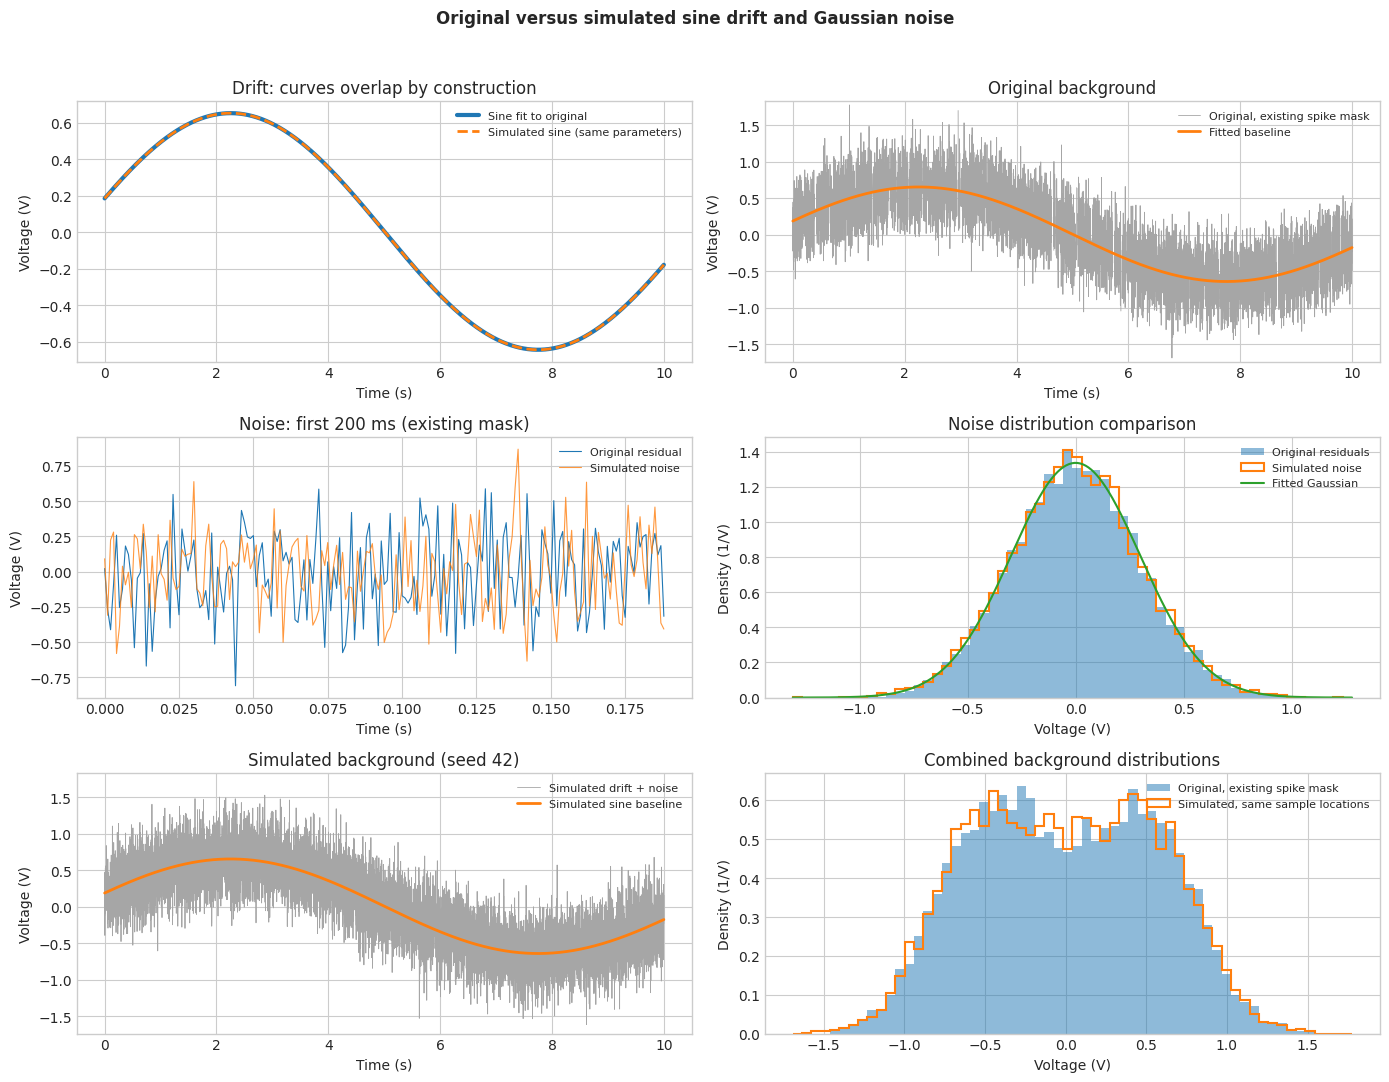

In [6]:
# Reproduce fitted background properties without changing any spike code.
background_rng = np.random.default_rng(42)
drift_sim = sine_model(t_orig, *popt_sine)
noise_sim = background_rng.normal(mu_original, sigma_original, size=N)
background_sim = drift_sim + noise_sim
noise_sim_comparison = noise_sim[mask_clean]

comparison_table = pd.DataFrame({
    'Quantity': ['Sine amplitude (V)', 'Sine frequency (Hz)',
                'Sine phase (rad)', 'Sine offset (V)',
                'Noise mean (V)', 'Noise standard deviation (V)',
                'Background mean (V)', 'Background standard deviation (V)'],
    'Original fit / retained samples': [A_sine, f_sine, phi_sine, C_sine,
        mu_original, sigma_original, raw_orig[mask_clean].mean(),
        raw_orig[mask_clean].std(ddof=0)],
    'Simulation / same retained locations': [A_sine, f_sine, phi_sine, C_sine,
        noise_sim_comparison.mean(), noise_sim_comparison.std(ddof=0),
        background_sim[mask_clean].mean(), background_sim[mask_clean].std(ddof=0)]
})
display(comparison_table)

fig, axes = plt.subplots(3, 2, figsize=(14, 11))
axes[0, 0].plot(t_orig, drift_original, lw=3, label='Sine fit to original')
axes[0, 0].plot(t_orig, drift_sim, '--', lw=2, label='Simulated sine (same parameters)')
axes[0, 0].set(title='Drift: curves overlap by construction', xlabel='Time (s)', ylabel='Voltage (V)')
axes[0, 0].legend(fontsize=8)

axes[0, 1].plot(t_orig, np.where(mask_clean, raw_orig, np.nan), color='0.65', lw=0.6,
                 label='Original, existing spike mask')
axes[0, 1].plot(t_orig, drift_original, color='C1', lw=2, label='Fitted baseline')
axes[0, 1].set(title='Original background', xlabel='Time (s)', ylabel='Voltage (V)')
axes[0, 1].legend(fontsize=8)

# A short segment makes individual noise fluctuations visible.
zoom = t_orig < t_orig[0] + 0.2
axes[1, 0].plot(t_orig[zoom], residual_trace[zoom], lw=0.8, label='Original residual')
axes[1, 0].plot(t_orig[zoom], np.where(mask_clean, noise_sim, np.nan)[zoom],
                 lw=0.8, alpha=0.8, label='Simulated noise')
axes[1, 0].set(title='Noise: first 200 ms (existing mask)', xlabel='Time (s)', ylabel='Voltage (V)')
axes[1, 0].legend(fontsize=8)

hist_bins = np.linspace(min(noise_original.min(), noise_sim_comparison.min()),
                         max(noise_original.max(), noise_sim_comparison.max()), 61)
axes[1, 1].hist(noise_original, bins=hist_bins, density=True, alpha=0.5, label='Original residuals')
axes[1, 1].hist(noise_sim_comparison, bins=hist_bins, density=True, histtype='step',
                 lw=1.5, label='Simulated noise')
grid = np.linspace(hist_bins[0], hist_bins[-1], 400)
axes[1, 1].plot(grid, stats.norm.pdf(grid, mu_original, sigma_original),
                 label='Fitted Gaussian')
axes[1, 1].set(title='Noise distribution comparison', xlabel='Voltage (V)', ylabel='Density (1/V)')
axes[1, 1].legend(fontsize=8)

axes[2, 0].plot(t_orig, background_sim, color='0.65', lw=0.6, label='Simulated drift + noise')
axes[2, 0].plot(t_orig, drift_sim, color='C1', lw=2, label='Simulated sine baseline')
axes[2, 0].set(title='Simulated background (seed 42)', xlabel='Time (s)', ylabel='Voltage (V)')
axes[2, 0].legend(fontsize=8)
# Match limits so the original and simulated backgrounds can be compared fairly.
low = min(raw_orig[mask_clean].min(), background_sim.min())
high = max(raw_orig[mask_clean].max(), background_sim.max())
for ax in [axes[0, 1], axes[2, 0]]:
    ax.set_ylim(low - 0.05, high + 0.05)

background_bins = np.linspace(min(raw_orig[mask_clean].min(), background_sim[mask_clean].min()),
                              max(raw_orig[mask_clean].max(), background_sim[mask_clean].max()), 61)
axes[2, 1].hist(raw_orig[mask_clean], bins=background_bins, density=True, alpha=0.5,
                 label='Original, existing spike mask')
axes[2, 1].hist(background_sim[mask_clean], bins=background_bins, density=True,
                 histtype='step', lw=1.5, label='Simulated, same sample locations')
axes[2, 1].set(title='Combined background distributions', xlabel='Voltage (V)', ylabel='Density (1/V)')
axes[2, 1].legend(fontsize=8)
fig.suptitle('Original versus simulated sine drift and Gaussian noise', fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()
